# PlantVillage — Model Evaluation and Comparison

This notebook performs the final evaluation and comparison of the PlantVillage disease-classification models developed in the previous stages.

The baseline CNN and EfficientNetB0 are compared using overall accuracy, macro-averaged metrics, per-class F1-score, confusion matrices, and error analysis.

The objective is to determine which model should be selected for the subsequent explainability and deployment stages of AgriVision AI.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
)

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "plantvillage"
MODEL_DIR = PROJECT_ROOT / "models"

TEST_PATH = DATA_DIR / "test.csv"

EFFICIENTNET_PATH = MODEL_DIR / "plantvillage_efficientnetb0.keras"
BASELINE_CNN_PATH = MODEL_DIR / "plantvillage_baseline_cnn.keras"

IMG_SIZE = (256, 256)
BATCH_SIZE = 32
RANDOM_SEED = 9

tf.random.set_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

In [3]:
test_df = pd.read_csv(TEST_PATH)

print(f"Test images: {len(test_df):,}")
print(f"Test classes: {test_df['class_id'].nunique()}")

Test images: 8,146
Test classes: 38


In [4]:
class_ids = sorted(test_df["class_id"].unique())

class_to_index = {
    class_id: index
    for index, class_id in enumerate(class_ids)
}

index_to_class = {
    index: class_id
    for class_id, index in class_to_index.items()
}

test_df["label"] = test_df["class_id"].map(class_to_index)

NUM_CLASSES = len(class_ids)

print("Number of classes:", NUM_CLASSES)

Number of classes: 38


In [5]:
def resolve_paths(df):
    paths = []

    for path in df["image_path"]:
        image_path = PROJECT_ROOT / path

        if not image_path.exists():
            raise FileNotFoundError(
                f"Image not found: {image_path}"
            )

        paths.append(str(image_path))

    return paths


test_paths = resolve_paths(test_df)

print("Test image paths verified.")

Test image paths verified.


In [6]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label


test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_df["label"].values)
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE,
)

test_dataset = test_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

print("Test dataset ready.")

Test dataset ready.


In [7]:
BASELINE_IMG_SIZE = (128, 128)


def load_baseline_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, BASELINE_IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


baseline_test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_df["label"].values)
)

baseline_test_dataset = baseline_test_dataset.map(
    load_baseline_image,
    num_parallel_calls=tf.data.AUTOTUNE,
)

baseline_test_dataset = baseline_test_dataset.batch(BATCH_SIZE)
baseline_test_dataset = baseline_test_dataset.prefetch(
    tf.data.AUTOTUNE
)

print("Baseline test dataset ready.")

Baseline test dataset ready.


In [8]:
efficientnet = tf.keras.models.load_model(
    EFFICIENTNET_PATH
)

print("EfficientNetB0 loaded.")

EfficientNetB0 loaded.


In [9]:
y_true = test_df["label"].values

probabilities = efficientnet.predict(
    test_dataset,
    verbose=1,
)

y_pred = np.argmax(
    probabilities,
    axis=1,
)

confidence = np.max(
    probabilities,
    axis=1,
)

print("Predictions:", len(y_pred))

255/255 ━━━━━━━━━━━━━━━━━━━━ 55s 213ms/step
Predictions: 8146


In [10]:
target_names = [
    test_df.loc[
        test_df["class_id"] == index_to_class[i],
        "class_name"
    ].iloc[0]
    for i in range(NUM_CLASSES)
]

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=target_names,
    output_dict=True,
)

report_df = (
    pd.DataFrame(report_dict)
    .T
)

report_df

,precision,recall,f1-score,support
Apple___Apple_scab,0.989362,0.989362,0.989362,94.000000
Apple___Black_rot,0.968750,1.000000,0.984127,93.000000
Apple___Cedar_apple_rust,1.000000,1.000000,1.000000,41.000000
Apple___healthy,1.000000,1.000000,1.000000,247.000000
Blueberry___healthy,1.000000,1.000000,1.000000,226.000000
Cherry_(including_sour)___Powdery_mildew,0.993711,1.000000,0.996845,158.000000
Cherry_(including_sour)___healthy,1.000000,1.000000,1.000000,128.000000
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.922078,0.922078,0.922078,77.000000
Corn_(maize)___Common_rust_,1.000000,1.000000,1.000000,179.000000
Corn_(maize)___Northern_Leaf_Blight,0.952381,0.952381,0.952381,147.000000


In [11]:
efficientnet_accuracy = report_dict["accuracy"]
efficientnet_macro_f1 = report_dict["macro avg"]["f1-score"]
efficientnet_macro_precision = report_dict["macro avg"]["precision"]
efficientnet_macro_recall = report_dict["macro avg"]["recall"]
efficientnet_weighted_f1 = report_dict["weighted avg"]["f1-score"]

print(f"Accuracy:          {efficientnet_accuracy:.4f}")
print(f"Macro Precision:   {efficientnet_macro_precision:.4f}")
print(f"Macro Recall:      {efficientnet_macro_recall:.4f}")
print(f"Macro F1:          {efficientnet_macro_f1:.4f}")
print(f"Weighted F1:       {efficientnet_weighted_f1:.4f}")

Accuracy:          0.9883
Macro Precision:   0.9851
Macro Recall:      0.9809
Macro F1:          0.9826
Weighted F1:       0.9883


In [12]:
baseline_cnn = tf.keras.models.load_model(
    BASELINE_CNN_PATH
)
print("Baseline CNN loaded.")

Baseline CNN loaded.


In [13]:
y_true = test_df["label"].values

baseline_probabilities = baseline_cnn.predict(
    baseline_test_dataset,
    verbose=1,
)

y_pred_baseline = np.argmax(
    baseline_probabilities,
    axis=1,
)

baseline_confidence = np.max(
    baseline_probabilities,
    axis=1,
)

print("Baseline predictions:", len(y_pred_baseline))

255/255 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step
Baseline predictions: 8146


In [14]:
target_names = [
    test_df.loc[
        test_df["class_id"] == index_to_class[i],
        "class_name"
    ].iloc[0]
    for i in range(NUM_CLASSES)
]

report_dict = classification_report(
    y_true,
    y_pred_baseline,
    target_names=target_names,
    output_dict=True,
)

report_df_baseline = (
    pd.DataFrame(report_dict)
    .T
)

report_df_baseline

,precision,recall,f1-score,support
Apple___Apple_scab,0.952381,0.851064,0.898876,94.000000
Apple___Black_rot,0.955556,0.924731,0.939891,93.000000
Apple___Cedar_apple_rust,0.918919,0.829268,0.871795,41.000000
Apple___healthy,0.884758,0.963563,0.922481,247.000000
Blueberry___healthy,0.961039,0.982301,0.971554,226.000000
Cherry_(including_sour)___Powdery_mildew,0.980892,0.974684,0.977778,158.000000
Cherry_(including_sour)___healthy,0.932836,0.976562,0.954198,128.000000
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.836735,0.532468,0.650794,77.000000
Corn_(maize)___Common_rust_,1.000000,0.983240,0.991549,179.000000
Corn_(maize)___Northern_Leaf_Blight,0.760000,0.904762,0.826087,147.000000


In [15]:
baseline_report = classification_report(
    y_true,
    y_pred_baseline,
    target_names=target_names,
    output_dict=True,
)

baseline_accuracy = baseline_report["accuracy"]
baseline_macro_precision = baseline_report["macro avg"]["precision"]
baseline_macro_recall = baseline_report["macro avg"]["recall"]
baseline_macro_f1 = baseline_report["macro avg"]["f1-score"]
baseline_weighted_f1 = baseline_report["weighted avg"]["f1-score"]

print(f"Baseline Accuracy:          {baseline_accuracy:.4f}")
print(f"Baseline Macro Precision:   {baseline_macro_precision:.4f}")
print(f"Baseline Macro Recall:      {baseline_macro_recall:.4f}")
print(f"Baseline Macro F1-Score:    {baseline_macro_f1:.4f}")
print(f"Baseline Weighted F1-Score: {baseline_weighted_f1:.4f}")

Baseline Accuracy:          0.9368
Baseline Macro Precision:   0.9274
Baseline Macro Recall:      0.9052
Baseline Macro F1-Score:    0.9136
Baseline Weighted F1-Score: 0.9363


In [16]:
comparison = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
    ],
    "Baseline CNN": [
        baseline_accuracy,
        baseline_macro_precision,
        baseline_macro_recall,
        baseline_macro_f1,
        baseline_weighted_f1,
    ],
    "EfficientNetB0": [
        efficientnet_accuracy,
        efficientnet_macro_precision,
        efficientnet_macro_recall,
        efficientnet_macro_f1,
        efficientnet_weighted_f1,
    ],
})

comparison["Improvement"] = (
    comparison["EfficientNetB0"]
    - comparison["Baseline CNN"]
)

comparison

,Metric,Baseline CNN,EfficientNetB0,Improvement
0,Test Accuracy,0.936779,0.988338,0.051559
1,Macro Precision,0.927429,0.985075,0.057646
2,Macro Recall,0.905179,0.980900,0.075721
3,Macro F1,0.913585,0.982594,0.069010
4,Weighted F1,0.936273,0.988311,0.052038


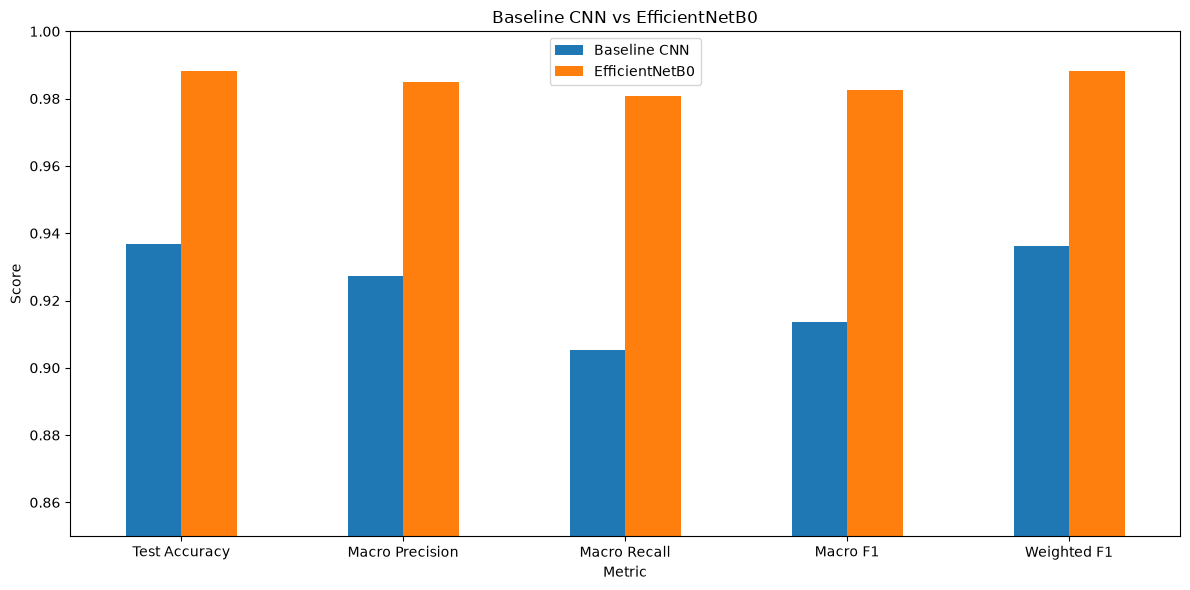

In [17]:
plot_df = comparison.set_index("Metric")[
    ["Baseline CNN", "EfficientNetB0"]
]

plot_df.plot(
    kind="bar",
    figsize=(12, 6),
)

plt.title("Baseline CNN vs EfficientNetB0")
plt.ylabel("Score")
plt.ylim(0.85, 1.0)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
class_results = (
    report_df.loc[
        report_df.index.isin(target_names),
        ["precision", "recall", "f1-score", "support"]
    ]
    .sort_values(by="f1-score")
)

class_results.head(10)

,precision,recall,f1-score,support
Potato___healthy,1.000000,0.782609,0.878049,23.0
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.922078,0.922078,0.922078,77.0
Tomato___Early_blight,0.916129,0.946667,0.931148,150.0
Tomato___Target_Spot,0.943396,0.952381,0.947867,210.0
Corn_(maize)___Northern_Leaf_Blight,0.952381,0.952381,0.952381,147.0
Tomato___Leaf_Mold,0.971014,0.937063,0.953737,143.0
Tomato___Spider_mites Two-spotted_spider_mite,0.968127,0.964286,0.966203,252.0
Potato___Late_blight,0.966887,0.973333,0.970100,150.0
Tomato___Late_blight,0.972028,0.968641,0.970332,287.0
Tomato___Septoria_leaf_spot,0.984791,0.973684,0.979206,266.0


In [19]:
confidence_df = pd.DataFrame({
    "true_label": y_true,
    "predicted_label": y_pred,
    "confidence": confidence,
})

confidence_df["true_class"] = confidence_df["true_label"].map(
    dict(enumerate(target_names))
)

confidence_df["predicted_class"] = confidence_df["predicted_label"].map(
    dict(enumerate(target_names))
)

confidence_df["correct"] = (
    confidence_df["true_label"]
    == confidence_df["predicted_label"]
)

print(
    "Average confidence:",
    confidence_df["confidence"].mean()
)

print(
    "Average confidence on correct predictions:",
    confidence_df.loc[
        confidence_df["correct"],
        "confidence"
    ].mean()
)

print(
    "Average confidence on incorrect predictions:",
    confidence_df.loc[
        ~confidence_df["correct"],
        "confidence"
    ].mean()
)

Average confidence: 0.9934049
Average confidence on correct predictions: 0.995651
Average confidence on incorrect predictions: 0.80305827


In [20]:
incorrect = confidence_df[
    ~confidence_df["correct"]
].sort_values(
    "confidence",
    ascending=False,
)

print(f"Incorrect predictions: {len(incorrect):,}")

incorrect[
    [
        "true_class",
        "predicted_class",
        "confidence",
    ]
].head(20)

Incorrect predictions: 95


,true_class,predicted_class,confidence
1025,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,1.000000
1253,Potato___Late_blight,Tomato___Late_blight,0.999893
2116,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,0.999843
1482,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,0.999780
5341,Tomato___Bacterial_spot,Tomato___Target_Spot,0.999297
5155,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,0.999219
610,Tomato___Early_blight,Tomato___Late_blight,0.998848
4623,Potato___healthy,Soybean___healthy,0.998680
370,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,0.997369
5515,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,0.996657


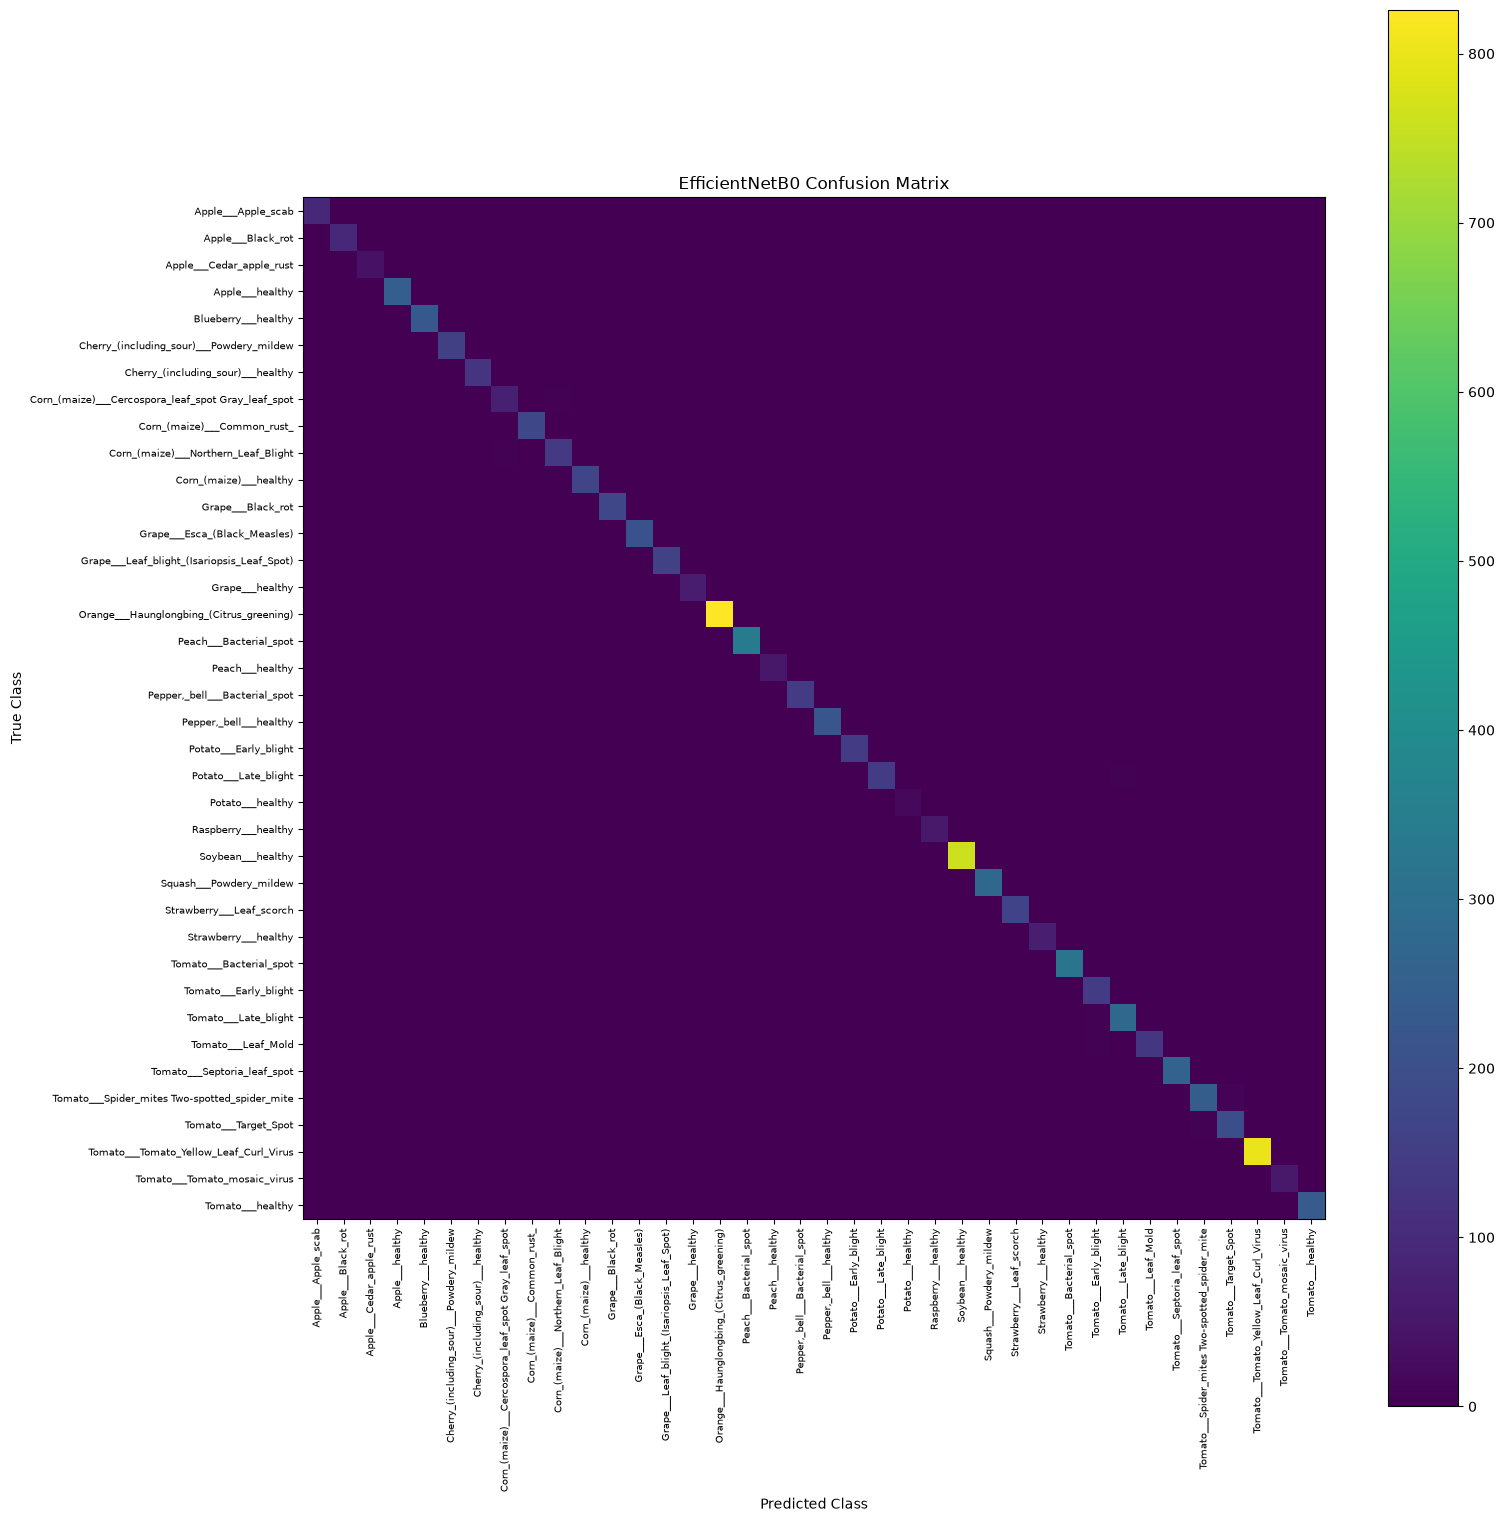

In [21]:
cm = confusion_matrix(
    y_true,
    y_pred,
)

plt.figure(figsize=(16, 16))

plt.imshow(
    cm,
    interpolation="nearest",
)

plt.title("EfficientNetB0 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    target_names,
    rotation=90,
    fontsize=7,
)

plt.yticks(
    range(NUM_CLASSES),
    target_names,
    fontsize=7,
)

plt.tight_layout()
plt.show()

In [22]:
confusion_pairs = []

for true_idx in range(NUM_CLASSES):
    for pred_idx in range(NUM_CLASSES):
        if true_idx != pred_idx and cm[true_idx, pred_idx] > 0:
            confusion_pairs.append({
                "true_class": target_names[true_idx],
                "predicted_class": target_names[pred_idx],
                "errors": cm[true_idx, pred_idx],
            })

confusion_pairs_df = (
    pd.DataFrame(confusion_pairs)
    .sort_values("errors", ascending=False)
)

confusion_pairs_df.head(15)

,true_class,predicted_class,errors
44,Tomato___Spider_mites Two-spotted_spider_mite,Tomato___Target_Spot,7
2,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,6
1,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,6
48,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,5
34,Tomato___Leaf_Mold,Tomato___Early_blight,4
29,Tomato___Late_blight,Tomato___Early_blight,4
12,Potato___Late_blight,Tomato___Late_blight,4
37,Tomato___Leaf_Mold,Tomato___Tomato_Yellow_Leaf_Curl_Virus,3
10,Potato___Early_blight,Potato___Late_blight,3
27,Tomato___Early_blight,Tomato___Tomato_Yellow_Leaf_Curl_Virus,2


In [23]:
previously_weak = [
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Tomato___Early_blight",
    "Potato___Late_blight",
    "Tomato___Leaf_Mold",
    "Corn_(maize)___Northern_Leaf_Blight",
]

class_results.loc[
    class_results.index.intersection(previously_weak)
]

,precision,recall,f1-score,support
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.922078,0.922078,0.922078,77.0
Tomato___Early_blight,0.916129,0.946667,0.931148,150.0
Corn_(maize)___Northern_Leaf_Blight,0.952381,0.952381,0.952381,147.0
Tomato___Leaf_Mold,0.971014,0.937063,0.953737,143.0
Potato___Late_blight,0.966887,0.973333,0.970100,150.0


In [24]:
EVALUATION_DIR = DATA_DIR / "evaluation"
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

class_results.to_csv(
    EVALUATION_DIR / "efficientnet_classification_report.csv"
)

comparison.to_csv(
    EVALUATION_DIR / "model_comparison.csv",
    index=False,
)

confusion_pairs_df.to_csv(
    EVALUATION_DIR / "confusion_pairs.csv",
    index=False,
)

print("✓ Evaluation results saved.")

✓ Evaluation results saved.


## Final Model Evaluation and Selection

The final evaluation compared the baseline CNN and EfficientNetB0 on the same held-out PlantVillage test set of 8,146 images.

Both models were evaluated using the same ground-truth labels, while each model retained the input preprocessing used during its training:

- Baseline CNN: 128 × 128 input with pixel normalization
- EfficientNetB0: 256 × 256 input

### Model Comparison

| Metric | Baseline CNN | EfficientNetB0 |
|---|---:|---:|
| Test Accuracy | 93.68% | **98.83%** |
| Macro Precision | 92.74% | **98.51%** |
| Macro Recall | 90.52% | **98.09%** |
| Macro F1 | 91.36% | **98.26%** |
| Weighted F1 | 93.63% | **98.83%** |

EfficientNetB0 improved test accuracy by **5.15 percentage points** and macro F1-score by **6.90 percentage points** compared with the baseline CNN.

### Error Analysis

The remaining EfficientNetB0 errors are concentrated mainly among visually similar disease classes.

The largest confusion pairs include:

- Tomato Spider Mites → Tomato Target Spot: 7 errors
- Corn Northern Leaf Blight → Corn Cercospora / Gray Leaf Spot: 6 errors
- Corn Cercospora / Gray Leaf Spot → Corn Northern Leaf Blight: 6 errors
- Tomato Target Spot → Tomato Spider Mites: 5 errors
- Tomato Leaf Mold → Tomato Early Blight: 4 errors
- Tomato Late Blight → Tomato Early Blight: 4 errors

This indicates that the model has largely learned to distinguish different crops and disease categories, while the remaining errors are concentrated among visually similar conditions.

### Improvement on Previously Difficult Classes

The classes that performed poorly with the baseline CNN showed substantial improvement with EfficientNetB0.

| Class | Baseline F1 | EfficientNetB0 F1 |
|---|---:|---:|
| Corn Cercospora / Gray Leaf Spot | 65.08% | **92.21%** |
| Tomato Early Blight | 73.88% | **93.11%** |
| Corn Northern Leaf Blight | 82.61% | **95.24%** |
| Tomato Leaf Mold | 82.95% | **95.37%** |
| Potato Late Blight | 82.04% | **97.01%** |

The improvement in these classes shows that the benefit of transfer learning is not limited to the most frequently represented classes.

### Confidence Analysis

The confidence analysis also identified some incorrect predictions made with very high confidence. This demonstrates that a high softmax confidence score should not automatically be interpreted as a calibrated probability of correctness.

This will be important when designing the final prediction API, where model predictions should be presented carefully rather than treating confidence as absolute certainty.

### Final Model Selection

Based on the held-out test-set evaluation, **EfficientNetB0 is selected as the current best model for PlantVillage disease classification in AgriVision AI**.

It provides substantially better overall and class-balanced performance than the baseline CNN while also reducing errors in several of the classes identified as difficult during earlier analysis.

No additional class-balancing or augmentation techniques will be introduced at this stage because the current model already achieves strong performance across the 38 classes. Further improvements should only be pursued if later analysis identifies a specific limitation that justifies additional complexity.

The selected EfficientNetB0 model will now move to the explainability stage, where Grad-CAM will be used to investigate which regions of plant images contribute to the model's predictions.